[instructions & rubric](https://course.ccs.neu.edu/ds4400f26-higger/learn/puzzle_problems.html)

# Puzzle: Slice Crawl

There are 8 pizza shops near campus and you want to find the best one.
The catch: you learn about a shop only by tasting its slices.

**Your goal: taste as few slices as possible while still naming the best
shop with at least 95% confidence** (right in at least 95% of crawls).

Each slice gets a rating, but slices vary: the same shop can be great on
Tuesday and soggy on Friday. Each shop's ratings follow a bell curve around
that shop's typical rating, and some shops are more consistent than others.
You don't know any shop's typical rating or consistency.

`SliceCrawl` (in `slice_crawl.py`) runs one crawl. `crawl.taste(i)` buys a
slice from shop `i` and returns its rating. Write `estimate(crawl)`: taste
any shops you like, as many times as you like, then return the shop you
think is best.

- First, clear the bar: name the true best shop in at least 95% of crawls.
- Then, save pizza: among estimators that clear the bar, fewer slices
  (averaged over many crawls) is better.
- Practice on the
  [Slice Crawl site](https://matthigger.github.io/ml_puzzle/slice_crawl/#practice):
  it runs your `estimate()` on as many random crawls as you like and shows
  how it did.
- For fun, we'll race everyone's estimator head to head: fewest slices
  among those that clear 95% wins bragging rights (no effect on your grade).
  Post yours on the site's Leaderboard tab with class code `slice-n30b-xqvq-92e4`.

`evaluate(estimate)` runs your estimator on 200 random crawls and reports
how often it was right and how many slices it tasted on average (the same
`seed` always gives the same crawls). Anything on a crawl that starts with
an underscore (e.g. `crawl._mean`) is the hidden truth: peeking is
cheating. An example estimator:

In [1]:
from slice_crawl import SliceCrawl, evaluate

crawl = SliceCrawl.sample(seed=0)  # one random crawl of 8 shops
print(crawl.taste(3), crawl.taste(3), crawl.n_taste)


def taste_each_5(crawl):
    """ 5 slices from every shop, best average wins """
    avg = [sum(crawl.taste(i) for _ in range(5)) / 5
           for i in range(crawl.n_shop)]
    return avg.index(max(avg))


evaluate(taste_each_5);

5.5158722675697405 4.67064038868554 2
200 crawls: right 76.0% of the time (need 95%), 40.0 slices on average


## Executive summary

We built a method that finds the best of eight pizza shops while tasting as few slices as possible. It tastes a few slices everywhere, keeps tasting only the shops still in the running, and stops once it is confident. It names the right shop 96% of the time, clearing the 95% goal, using about 86 slices per crawl. For comparison, tasting 5 slices from every shop uses 40 slices but is right only 76% of the time.

In [2]:
import random
from slice_crawl import evaluate
from slice_helpers import N0, THRESHOLD, SEED, summarize, prob_best, taste_more


def estimate(crawl):
    """Taste until the leader's P(best) >= THRESHOLD, then name it."""
    rng = random.Random(SEED)
    ratings = [[crawl.taste(i) for _ in range(N0)] for i in range(crawl.n_shop)]
    summaries = [summarize(r) for r in ratings]          # steps 1-3
    while True:
        p = prob_best(summaries, rng)                    # steps 4-5
        if max(p) >= THRESHOLD:
            return p.index(max(p))
        taste_more(crawl, ratings, summaries, rng)       # step 6


evaluate(estimate);

200 crawls: right 97.5% of the time (need 95%), 97.0 slices on average


## Approach

We assume each shop's ratings follow a bell curve, so a shop tasted only a few times is uncertain. We taste 3 slices from each shop, then guess each shop's true average 500 times, spreading guesses wider for shops with fewer slices. The share of guesses a shop wins is its chance of being best. Once the leader's chance reaches 0.86, we name it. Otherwise, we taste more, mostly from the top two, and check again.

We chose 3 starting slices and the 0.86 cutoff by testing 21 combinations on 5,000 crawls each (table below), then confirmed it on 5,000 new crawls: 96.1% correct, 86 slices. A single 200-crawl run varies, like the one above (97.5%, 97 slices).

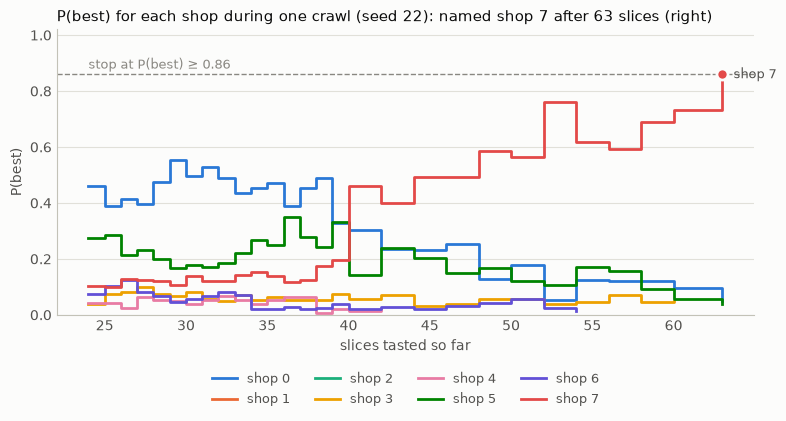

In [3]:
from slice_helpers import plot_pbest, plot_grid_table, plot_slices_per_shop

plot_pbest(seed=22)   # one close race: P(best) of each shop as slices are tasted

Shop 0 leads early, but shop 7 overtakes it around slice 40. Weak shops drop out quickly, and we stop at 63 slices once shop 7, the true best, reaches 0.86.

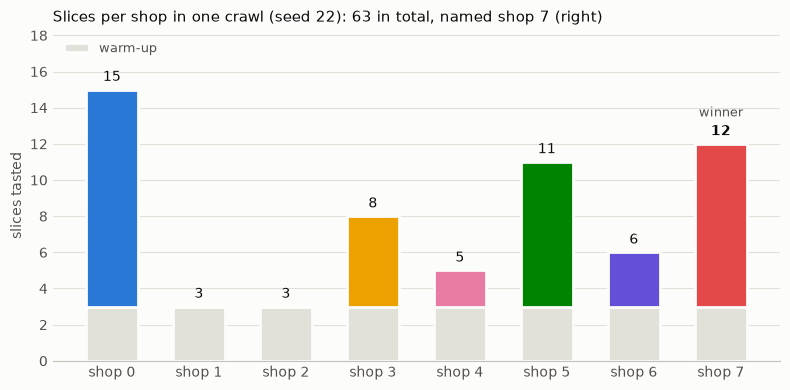

In [4]:
plot_slices_per_shop(seed=22)  # how many slices were tasted from each shop

Weak shops get only their 3 starting slices, while most extra slices go to the front-runners. Shop 0 got the most slices (15) because it led for most of the race. The method spends slices where the decision is hardest.

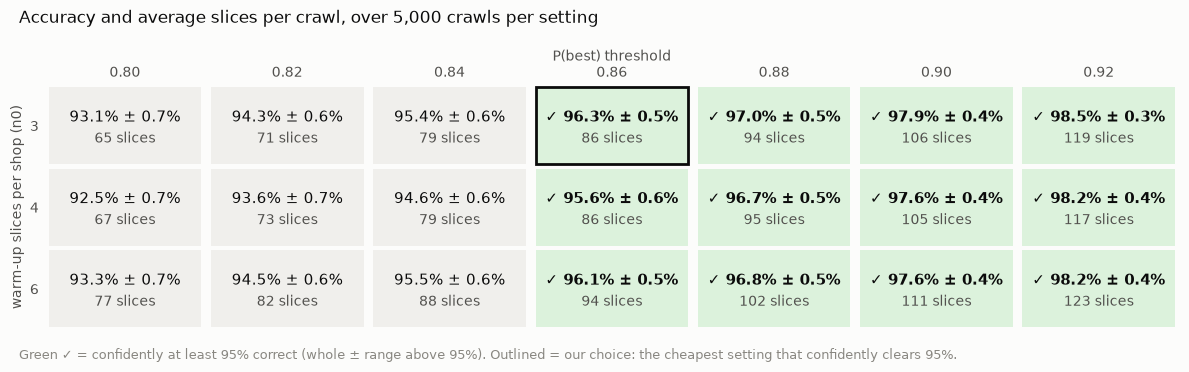

In [5]:
plot_grid_table()     # why n0=3, 0.86: reads grid_results.csv (made by run_grid(), ~20 min)

Lower thresholds save slices, but 0.86 is the lowest where we're confident accuracy stays above 95%.